In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
df = pd.read_csv("diabetes.csv")


In [2]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [3]:
df.tail

<bound method NDFrame.tail of      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   50 

In [4]:
df.shape

(768, 9)

In [5]:
df.dtypes


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.isnull()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
763,False,False,False,False,False,False,False,False,False
764,False,False,False,False,False,False,False,False,False
765,False,False,False,False,False,False,False,False,False
766,False,False,False,False,False,False,False,False,False


In [8]:
df.isnull().values.any()

np.False_

In [11]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [12]:
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


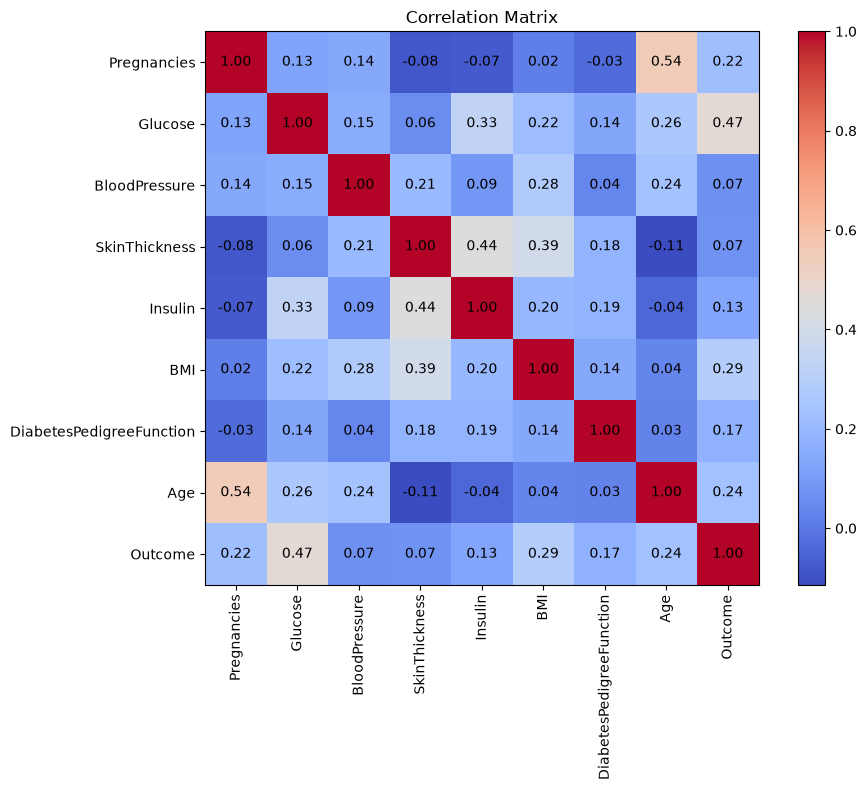

In [13]:
import matplotlib.pyplot as plt

corr = df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

# Print values inside the boxes
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.colorbar()
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

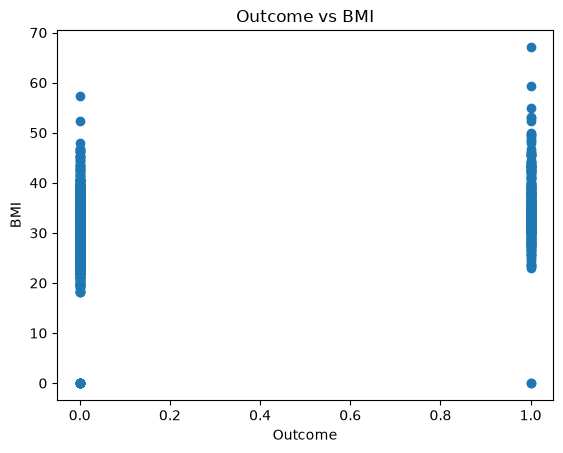

In [14]:
plt.scatter(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

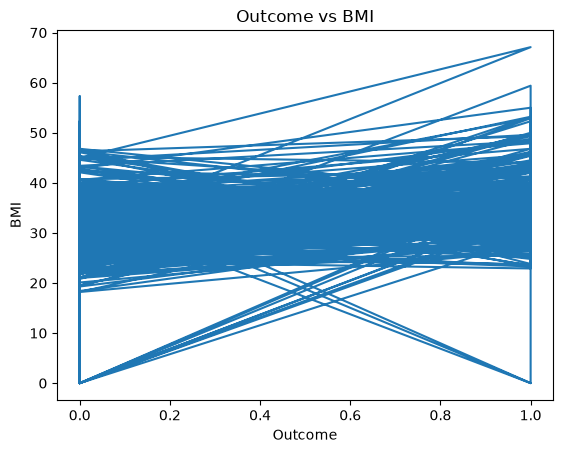

In [16]:
# 1. Line Plot
plt.plot(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

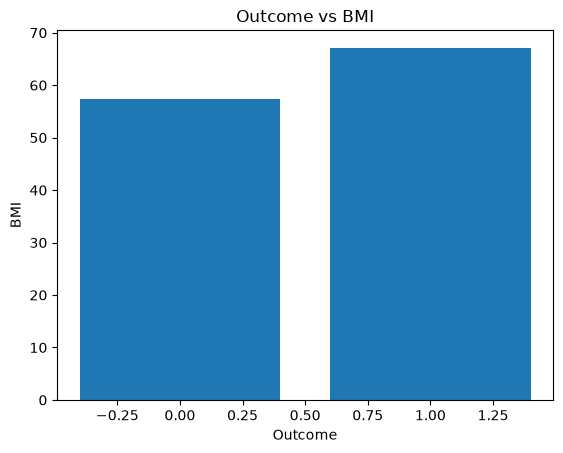

In [19]:
### 3. Bar Graph
plt.bar(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')
plt.show()

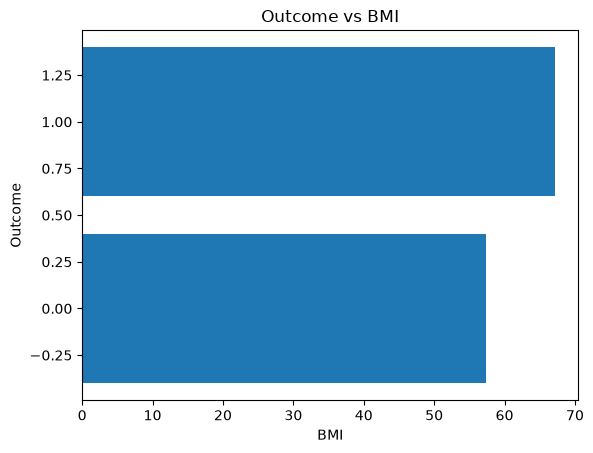

In [20]:
### 4. Horizontal Bar Graph


plt.barh(df['Outcome'], df['BMI'])

plt.xlabel('BMI')
plt.ylabel('Outcome')
plt.title('Outcome vs BMI')

plt.show()

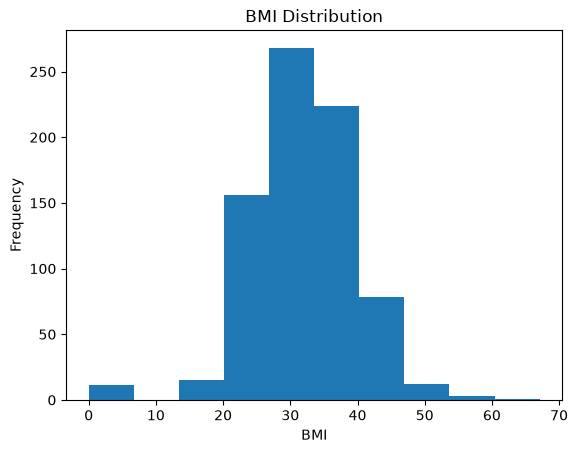

In [22]:
### 5. Histogram




plt.hist(df['BMI'])

plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.title('BMI Distribution')

plt.show()

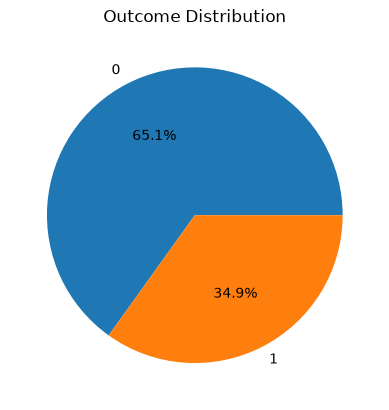

In [23]:

### 6. Pie Chart


df['Outcome'].value_counts().plot.pie(autopct='%1.1f%%')

plt.title('Outcome Distribution')

plt.show()

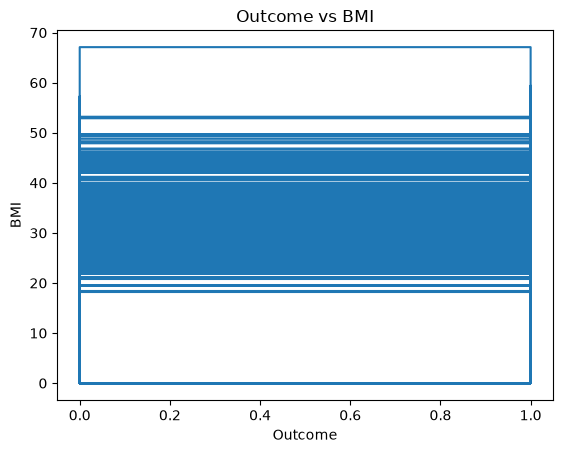

In [24]:
### 8. Step Plot


plt.step(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

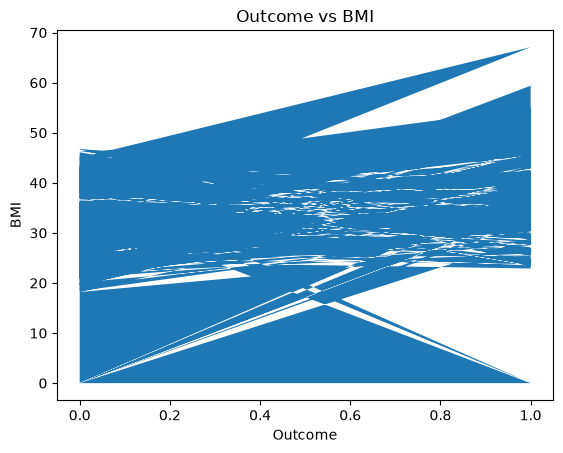

In [25]:
### 10. Area Plot

plt.fill_between(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

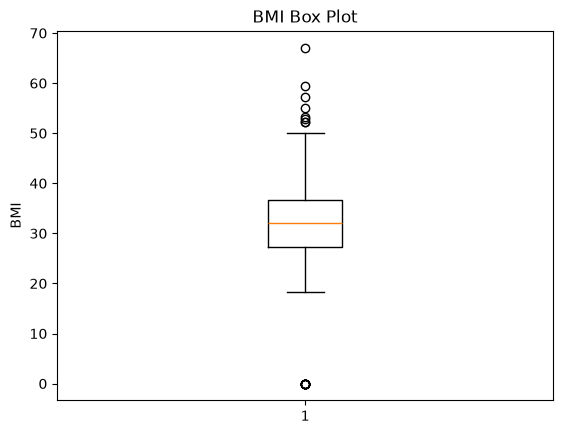

In [30]:
plt.boxplot(df['BMI'])

plt.ylabel('BMI')
plt.title('BMI Box Plot')

plt.show()

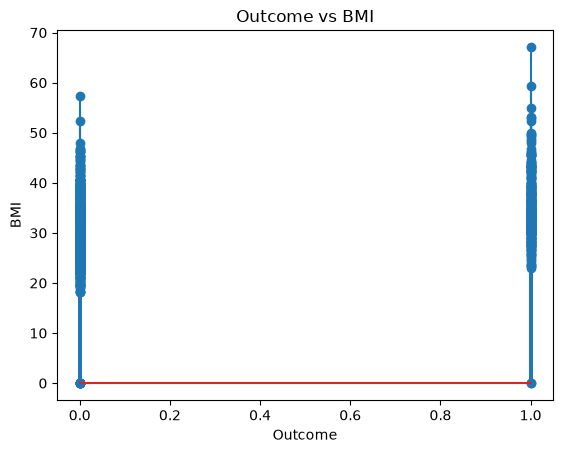

In [31]:
plt.stem(df['Outcome'], df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

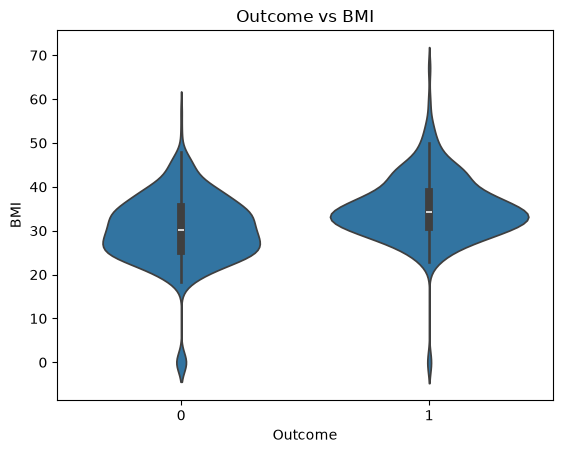

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.violinplot(x=df['Outcome'], y=df['BMI'])

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('Outcome vs BMI')

plt.show()

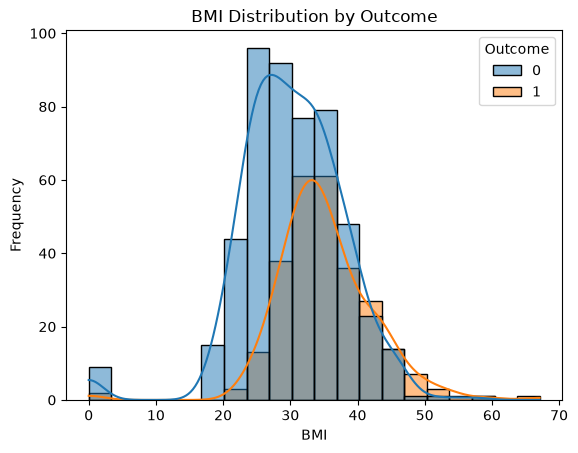

In [33]:
sns.histplot(data=df, x='BMI', hue='Outcome', bins=20, kde=True)

plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.title('BMI Distribution by Outcome')

plt.show()


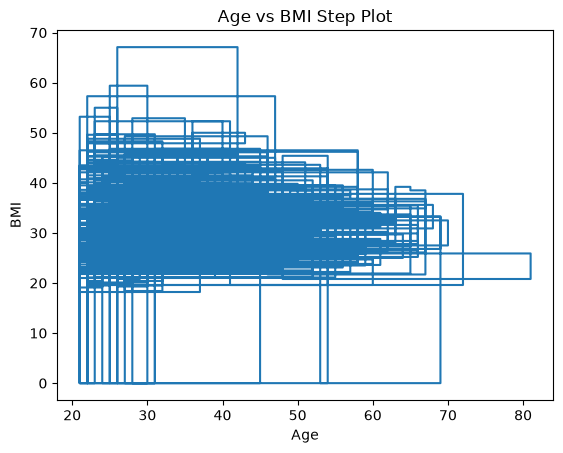

In [34]:
plt.step(df['Age'], df['BMI'])

plt.xlabel('Age')
plt.ylabel('BMI')
plt.title('Age vs BMI Step Plot')

plt.show()

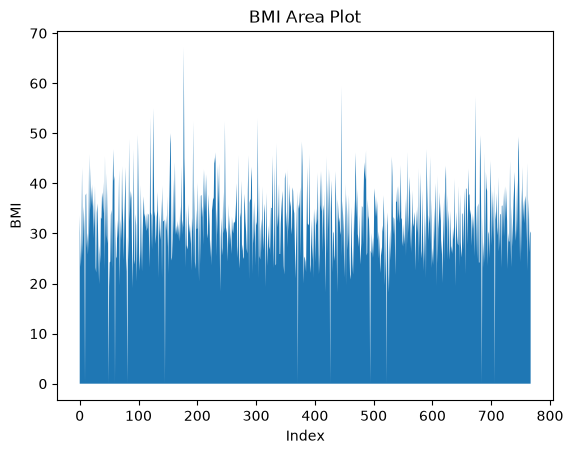

In [35]:
plt.fill_between(df.index, df['BMI'])

plt.xlabel('Index')
plt.ylabel('BMI')
plt.title('BMI Area Plot')

plt.show()

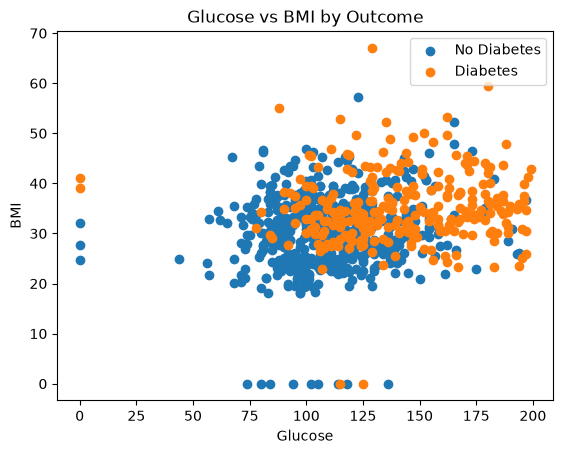

In [36]:
plt.scatter(
    df[df['Outcome'] == 0]['Glucose'],
    df[df['Outcome'] == 0]['BMI'],
    label='No Diabetes'
)

plt.scatter(
    df[df['Outcome'] == 1]['Glucose'],
    df[df['Outcome'] == 1]['BMI'],
    label='Diabetes'
)

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Glucose vs BMI by Outcome')
plt.legend()

plt.show()

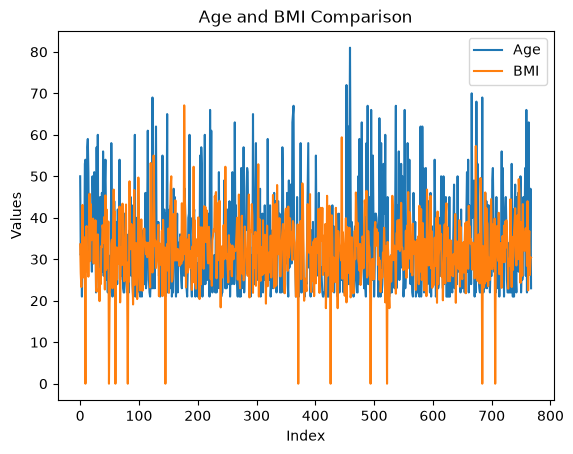

In [37]:
plt.plot(df['Age'], label='Age')
plt.plot(df['BMI'], label='BMI')

plt.xlabel('Index')
plt.ylabel('Values')
plt.title('Age and BMI Comparison')
plt.legend()

plt.show()

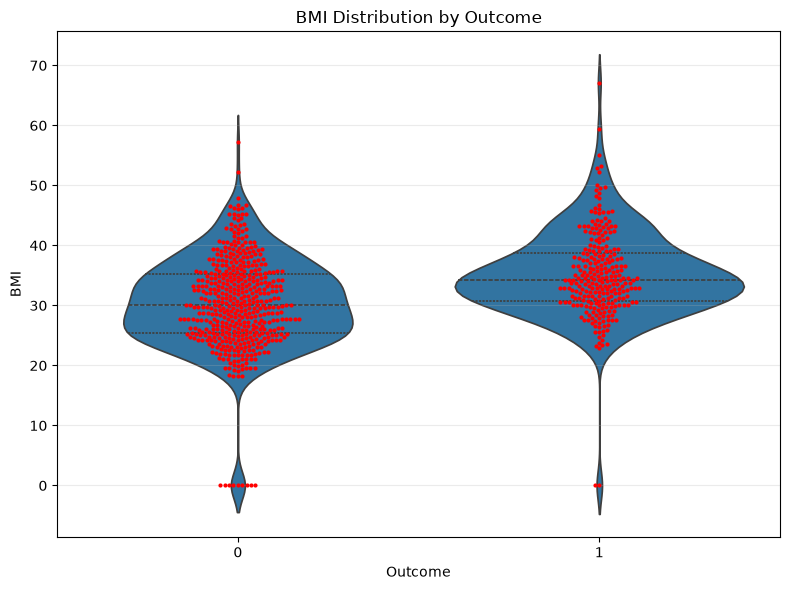

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.violinplot(
    data=df,
    x='Outcome',
    y='BMI',
    inner='quartile'
)

sns.swarmplot(
    data=df,
    x='Outcome',
    y='BMI',
    color='red',
    size=3
)

plt.xlabel('Outcome')
plt.ylabel('BMI')
plt.title('BMI Distribution by Outcome')

plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()